In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('respostas_formulario.csv')
df_alunos = pd.read_csv('alunos.csv')

df = df.drop_duplicates()
pd.set_option('display.width', 1000)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

# Mapeia as 6 dimensões do FunQ (blocos de 3 questões)
dimensoes = {
    'Autonomia': ['q1', 'q2', 'q3'],
    'Desafio': ['q4', 'q5', 'q6'],
    'Prazer': ['q7', 'q8', 'q9'],
    'Imersão': ['q10', 'q11', 'q12'],
    'Barreiras_Sociais': ['q13', 'q14', 'q15'],
    'Estresse': ['q16', 'q17', 'q18'],
}

## 📖 Dicionário de Variáveis — Questionário FunQ


### 1. Questões Padrões do FunQ (Q1 a Q18)
A tabela abaixo descreve o mapeamento entre os identificadores das variáveis no dataset (`q1` a `q18`), o enunciado de cada questão e a respectiva dimensão do engajamento avaliada.

| Código | Dimensão | Cód. FunQ | Enunciado da Questão | Escore Reverso? |
| :---:  | :---: | :---: | :---: | :---: |
| **q1** | **Autonomia** | **A1** | Eu sabia o que fazer. | Não |
| **q2** | **Autonomia** | **A2** | Eu fiz esta atividade porque eu tinha que fazer. | **Sim** |
| **q3** | **Autonomia** | **A3** | Fiz esta atividade porque eu quis. | Não |
| **q4** | **Desafio** | **C1** | Senti que eu era bom(boa) nesta atividade. | Não |
| **q5** | **Desafio** | **C2** | Eu fiz algo novo. | Não |
| **q6** | **Desafio** | **C3** | Fiquei curioso(a). | Não |
| **q7** | **Prazer** | **D1** | Eu me diverti. | Não |
| **q8** | **Prazer** | **D2** | Gostaria de fazer algo parecido novamente. | Não |
| **q9** | **Prazer** | **D3** | Senti-me feliz. | Não |
| **q10** | **Imersão** | **I1** | Senti que o tempo passou voando. | Não |
| **q11** | **Imersão** | **I2** | Esqueci da escola. | Não |
| **q12** | **Imersão** | **I3** | Senti-me bem. | Não |
| **q13** | **Barreiras Sociais** | **SB1** | Fiz novos amigos. | Não |
| **q14** | **Barreiras Sociais** | **SB2** | Conversei com outras pessoas mais facilmente do que o habitual. | Não |
| **q15** | **Barreiras Sociais** | **SB3** | Senti-me mais próximo(a) das outras pessoas do que o habitual. | Não |
| **q16** | **Estresse** | **S1** | Senti-me mal. | **Sim** |
| **q17** | **Estresse** | **S2** | Senti raiva. | **Sim** |
| **q18** | **Estresse** | **S3** | Senti-me triste. | **Sim** |

> **Nota Metodológica:** As questões marcadas com escore reverso já tiveram seus valores invertidos no pré-processamento do *back-end* ($\text{Novo Valor} = 6 - \text{Valor Antigo}$), garantindo que em todas as colunas uma nota mais alta signifique uma maior intensidade da dimensão avaliada.

---

### 2. Questões Abertas Padronizadas (Q19 a Q24)
> **Formato:** Texto livre (opcional para o participante). Utilizadas para triangulação qualitativa dos dados.

| Coluna / Código | Foco da Investigação |
| :---: | :--- |
| **q19_opiniao_atividade** | O que você achou da atividade realizada? |
| **q20_sentimento_jogo** | Como você se sentiu durante a realização do jogo? |
| **q21_compreensao_conceitos** | Você acredita que o jogo ajudou na compreensão dos conceitos trabalhados? |
| **q22_fator_interesse** | O que fez você permanecer interessado na atividade? |
| **q23_pontos_negativos** | O que você menos gostou na atividade? |
| **q24_sugestoes_mudanca** | O que você mudaria no jogo? |

---

In [2]:
# 1. Gera a lista de nomes das colunas de q1 até q18
colunas_questoes = [f'q{i}' for i in range(1, 19)]

df[colunas_questoes].head(10)

,q1,q2,q3,q4,q5,q6,q7,q8,q9,q10,q11,q12,q13,q14,q15,q16,q17,q18
0,2,1,3,2,2,4,4,2,3,4,4,2,2,3,2,2,3,4
1,4,3,3,4,3,4,3,4,3,4,3,4,4,3,3,4,3,4
2,2,2,2,3,3,2,3,3,5,3,2,2,2,4,2,3,2,3
3,4,1,3,3,4,4,2,2,3,4,1,5,1,3,4,4,4,5
4,3,1,3,3,4,4,5,3,3,2,2,4,4,2,3,3,3,3
5,4,4,3,4,4,2,4,4,3,4,4,3,4,5,4,4,5,1
6,3,3,3,2,3,4,3,3,3,4,3,3,3,2,3,3,5,4
7,4,3,3,4,3,2,4,3,3,4,4,3,4,4,3,3,3,2
8,5,3,4,5,4,4,5,5,5,3,5,5,5,4,5,2,5,5
9,2,4,3,3,2,3,4,3,4,3,4,4,3,3,4,2,3,2


---

In [3]:
display(df[['q19_opiniao_atividade', 'q20_sentimento_jogo', 'q21_compreensao_conceitos', 'q22_fator_interesse', 'q23_pontos_negativos', 'q24_sugestoes_mudanca']].head(10))

,q19_opiniao_atividade,q20_sentimento_jogo,q21_compreensao_conceitos,q22_fator_interesse,q23_pontos_negativos,q24_sugestoes_mudanca
0,"Preferia a aula tradicional, achei o jogo confuso.",Me senti perdido e com vergonha de perguntar para minha dupla.,Achei que faltou explicação antes de começar a jogar.,Quase nada me chamou atenção no jogo.,Faltou explicação e as perguntas sobre padrões estavam difíceis demais.,Simplificar o tabuleiro e explicar melhor as regras.
1,"Foi legal, mas achei um pouco longa.",NaN,Consegui entender só depois que o pesquisador explicou de novo.,O design das peças e do tabuleiro.,NaN,Ter mais tempo para treinar antes de valer ponto.
2,"Preferia a aula tradicional, achei o jogo confuso.",Me senti perdido e com vergonha de perguntar para minha dupla.,Achei que faltou explicação antes de começar a jogar.,"Só o final, quando acabou a atividade.",NaN,Diminuir o tempo da atividade.
3,"Gostei em parte, algumas regras do tabuleiro eram confusas.","Senti um pouco de tudo, às vezes empolgado, às vezes perdido.","Entendi o básico sobre os padrões, mas não tudo.",Jogar em dupla foi o que mais gostei.,Algumas perguntas do tabuleiro estavam confusas.,Dividir a atividade em duas aulas.
4,"Foi legal, mas achei um pouco longa.","Senti um pouco de tudo, às vezes empolgado, às vezes perdido.","Entendi a maior parte, mas ainda tenho dúvidas em alguns padrões.","As perguntas do tabuleiro, mas só nas primeiras rodadas.",Algumas perguntas do tabuleiro estavam confusas.,Ter mais tempo para treinar antes de valer ponto.
5,"Gostei em parte, algumas regras do tabuleiro eram confusas.","Senti um pouco de tudo, às vezes empolgado, às vezes perdido.",Consegui entender só depois que o pesquisador explicou de novo.,NaN,NaN,Ter mais tempo para treinar antes de valer ponto.
6,"Foi legal, mas achei um pouco longa.","Senti um pouco de tudo, às vezes empolgado, às vezes perdido.","Entendi a maior parte, mas ainda tenho dúvidas em alguns padrões.",NaN,NaN,Deixar as regras do tabuleiro mais claras no início.
7,NaN,"Senti um pouco de tudo, às vezes empolgado, às vezes perdido.","Entendi o básico sobre os padrões, mas não tudo.","As perguntas do tabuleiro, mas só nas primeiras rodadas.",Algumas perguntas do tabuleiro estavam confusas.,Ter mais tempo para treinar antes de valer ponto.
8,A atividade foi divertida e me fez prestar mais atenção.,Fiquei feliz e motivado durante todo o jogo.,NaN,Gostei das perguntas sobre padrões espalhadas pelo tabuleiro.,"Não vi pontos negativos, talvez o tempo curto de jogo.",Colocar mais casas e desafios diferentes no tabuleiro.
9,"Gostei em parte, algumas regras do tabuleiro eram confusas.","Fiquei um pouco ansioso no começo, depois relaxei.",Consegui entender só depois que o pesquisador explicou de novo.,O design das peças e do tabuleiro.,Algumas duplas atrapalharam a concentração.,Ter mais tempo para treinar antes de valer ponto.


---

In [4]:
display(df.iloc[[0]])

,id,aluno_id,grupo,pesquisador,q1,q2,q3,q4,q5,q6,q7,q8,q9,q10,q11,q12,q13,q14,q15,q16,q17,q18,q19_opiniao_atividade,q20_sentimento_jogo,q21_compreensao_conceitos,q22_fator_interesse,q23_pontos_negativos,q24_sugestoes_mudanca
0,1,1,Grupo A,Prof. Renata Campos,2,1,3,2,2,4,4,2,3,4,4,2,2,3,2,2,3,4,"Preferia a aula tradicional, achei o jogo confuso.",Me senti perdido e com vergonha de perguntar para minha dupla.,Achei que faltou explicação antes de começar a jogar.,Quase nada me chamou atenção no jogo.,Faltou explicação e as perguntas sobre padrões estavam difíceis demais.,Simplificar o tabuleiro e explicar melhor as regras.


---

In [5]:
# Média de cada dimensão por aluno

# Calcula a média de cada dimensão por resposta/aluno (axis=1 calcula por linha)
for nome_dimensao, colunas in dimensoes.items():
    df[nome_dimensao] = df[colunas].mean(axis=1)

# Exibe apenas a identificação da linha do aluno e as médias calculadas
colunas_resultado = ['aluno_id'] + list(dimensoes.keys())

display(df[colunas_resultado].head().round(2))

,aluno_id,Autonomia,Desafio,Prazer,Imersão,Barreiras_Sociais,Estresse
0,1,2.00,2.67,3.00,3.33,2.33,3.00
1,2,3.33,3.67,3.33,3.67,3.33,3.67
2,3,2.00,2.67,3.67,2.33,2.67,2.67
3,4,2.67,3.67,2.33,3.33,2.67,4.33
4,5,2.33,3.67,3.67,2.67,3.00,3.00


---

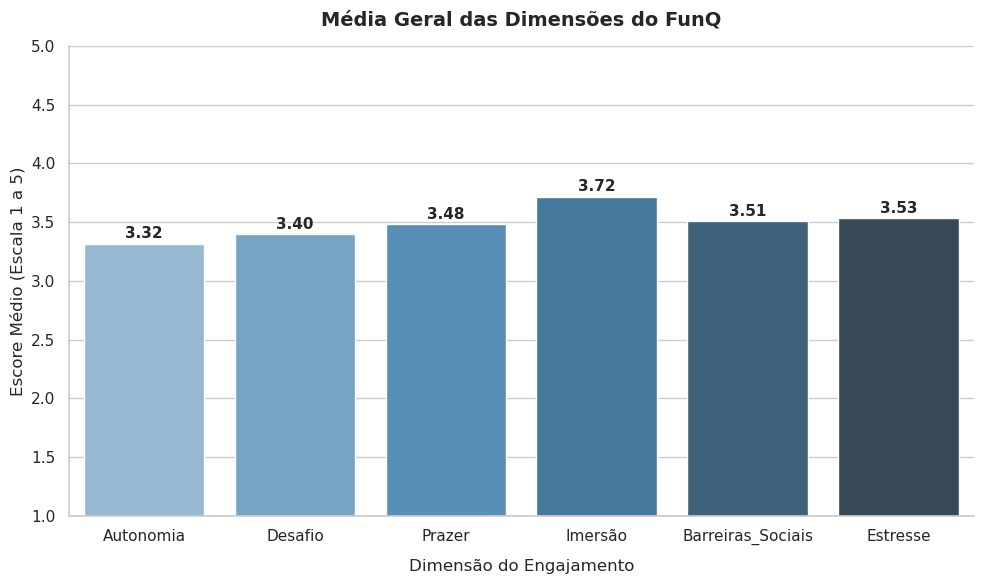

In [6]:
# Média geral das dimensões do FunQ

# Configura o estilo visual do gráfico para o padrão acadêmico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# 1. Calcula a média geral da turma para cada dimensão
medias_dimensoes = df[list(dimensoes.keys())].mean().reset_index()
medias_dimensoes.columns = ['Dimensão', 'Média']

# 2. Cria o gráfico de barras
ax = sns.barplot(
    x='Dimensão', 
    y='Média', 
    data=medias_dimensoes, 
    palette='Blues_d'
)

# 3. Adiciona os valores exatos no topo de cada barra
for p in ax.patches:
    altura = p.get_height()
    ax.annotate(
        f'{altura:.2f}',
        (p.get_x() + p.get_width() / 2., altura),
        ha='center', 
        va='center',
        xytext=(0, 7),
        textcoords='offset points',
        fontsize=11,
        fontweight='bold'
    )

# 4. Ajustes de títulos, eixos e escala Likert (1 a 5)
plt.title('Média Geral das Dimensões do FunQ', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Dimensão do Engajamento', fontsize=12, labelpad=10)
plt.ylabel('Escore Médio (Escala 1 a 5)', fontsize=12)
plt.ylim(1, 5)  # Fixa os limites no padrão da escala Likert do FunQ

# Remove bordas desnecessárias
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()

---

In [7]:
# Mediana e IQR por dimensão

# Dicionário para armazenar os cálculos de cada dimensão
estatisticas_dimensoes = {}

# Percorre cada dimensão com o laço for
for col in list(dimensoes.keys()):
    # Calcula a mediana
    mediana = df[col].median()
    
    # Calcula o IQR (Q3 - Q1)
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    
    # Salva os resultados no dicionário
    estatisticas_dimensoes[col] = {
        'Mediana': mediana,
        'IQR': iqr
    }

# Transforma o dicionário em um DataFrame do Pandas para exibir como tabela
df_mediana_iqr = pd.DataFrame(estatisticas_dimensoes).T

# Exibe o resultado formatado
display(df_mediana_iqr.round(2))

,Mediana,IQR
Autonomia,3.33,0.67
Desafio,3.33,1.00
Prazer,3.67,1.00
Imersão,3.67,1.00
Barreiras_Sociais,3.67,1.00
Estresse,3.67,0.75


---

In [8]:
# Desvio padrão por dimensão

# Dicionário para armazenar o desvio padrão de cada dimensão
estatisticas_desvio = {}

for col in list(dimensoes.keys()):
    # Calcula o desvio padrão (amostral, ddof=1 é o padrão do pandas)
    desvio_padrao = df[col].std()
    
    estatisticas_desvio[col] = {
        'Desvio Padrão': desvio_padrao
    }

df_desvio_padrao = pd.DataFrame(estatisticas_desvio).T

display(df_desvio_padrao.round(2))

,Desvio Padrão
Autonomia,0.81
Desafio,0.75
Prazer,0.82
Imersão,0.76
Barreiras_Sociais,0.75
Estresse,0.77


---

In [9]:
# Amplitude por dimensão

# Dicionário para armazenar a amplitude (máximo - mínimo) de cada dimensão
estatisticas_amplitude = {}

for col in list(dimensoes.keys()):
    valor_max = df[col].max()
    valor_min = df[col].min()
    amplitude = valor_max - valor_min
    
    estatisticas_amplitude[col] = {
        'Mínimo': valor_min,
        'Máximo': valor_max,
        'Amplitude': amplitude
    }

df_amplitude = pd.DataFrame(estatisticas_amplitude).T

display(df_amplitude.round(2))

,Mínimo,Máximo,Amplitude
Autonomia,1.67,4.67,3.00
Desafio,1.00,4.67,3.67
Prazer,1.00,5.00,4.00
Imersão,1.33,5.00,3.67
Barreiras_Sociais,1.33,5.00,3.67
Estresse,1.33,4.67,3.33


---

**Cruzamento/correlação entre as dimensões**

Desafio × Imersão → remete à Teoria do Fluxo (Csikszentmihalyi).

Estresse × Prazer → espera-se correlação negativa; se não aparecer, é um achado a discutir.

Autonomia × Prazer → autonomia costuma ser preditor de motivação intrínseca.

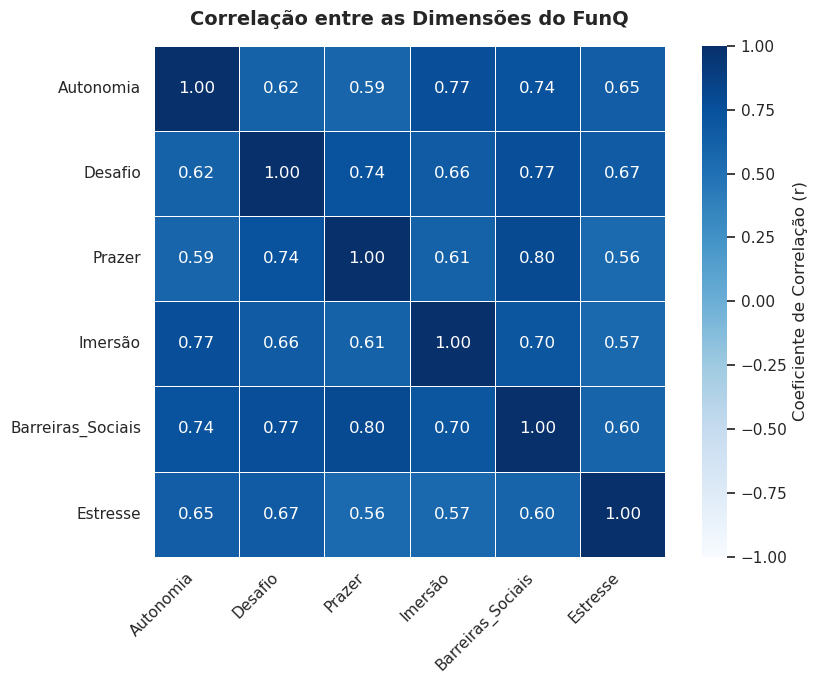

In [10]:
# Configura o estilo visual do gráfico para o padrão acadêmico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 7))

# 1. Seleciona apenas as colunas das dimensões
colunas_dim = list(dimensoes.keys())

# 2. Calcula a matriz de correlação entre as dimensões
matriz_correlacao = df[colunas_dim].corr(method='pearson')

# 3. Cria o heatmap
ax = sns.heatmap(
    matriz_correlacao,
    annot=True,            # mostra os valores dentro das células
    fmt='.2f',              # duas casas decimais
    cmap='Blues',            # paleta consistente com o gráfico de médias
    vmin=-1, vmax=1,         # fixa a escala de correlação (-1 a 1)
    square=True,
    linewidths=0.5,
    cbar_kws={'label': 'Coeficiente de Correlação (r)'}
)

# 4. Ajustes de título e eixos
plt.title('Correlação entre as Dimensões do FunQ', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('')
plt.ylabel('')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

---

**Idade como variável exploratória**

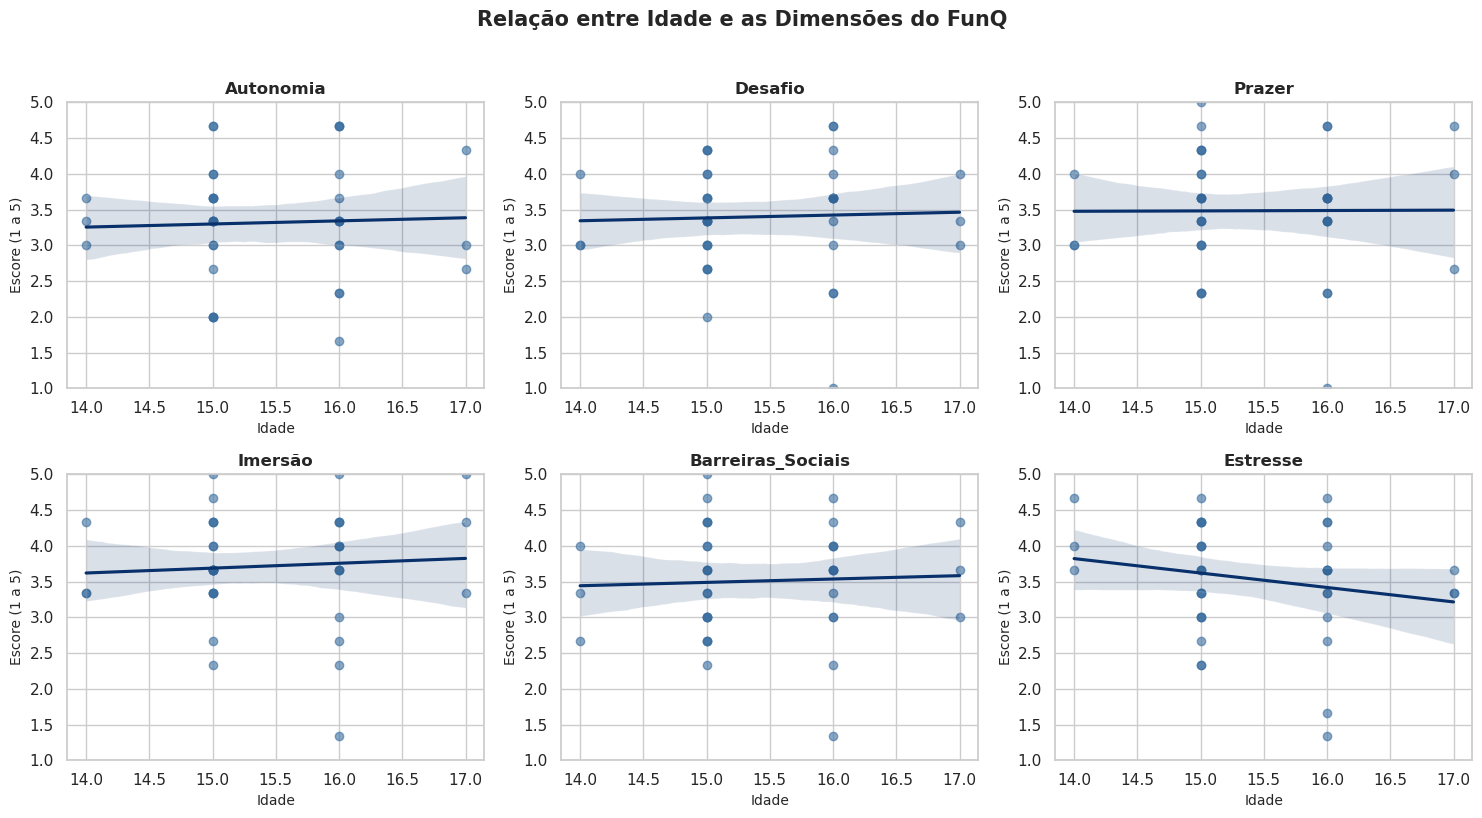

In [11]:
mapa_idade = df_alunos.set_index('id')['idade']

df_idade = df[['aluno_id'] + colunas_dim].copy()
df_idade['idade'] = df_idade['aluno_id'].map(mapa_idade)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(colunas_dim):
    sns.regplot(
        x='idade',
        y=col,
        data=df_idade,
        ax=axes[i],
        scatter_kws={'alpha': 0.6, 'color': '#3b6fa0'},
        line_kws={'color': '#08306b'}
    )
    axes[i].set_title(col, fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Idade', fontsize=10)
    axes[i].set_ylabel('Escore (1 a 5)', fontsize=10)
    axes[i].set_ylim(1, 5)

plt.suptitle('Relação entre Idade e as Dimensões do FunQ', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---

14-15 anos    23
16-17 anos    17
Name: faixa_etaria, dtype: int64


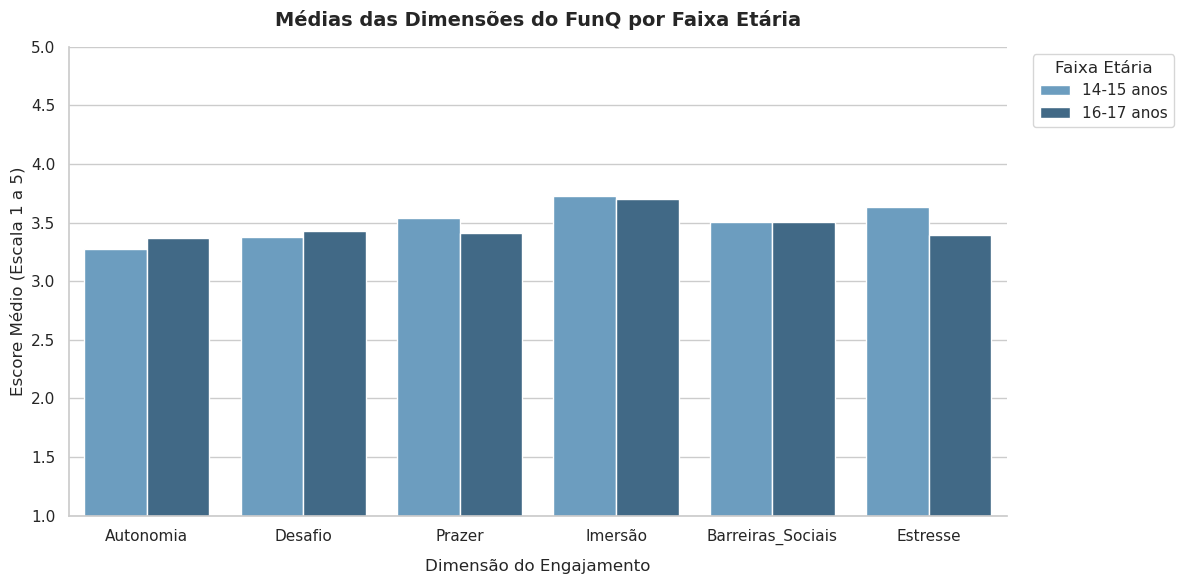

In [12]:
# Médias das Dimensões do FunQ por Faixa Etária

bins = [13, 15, 17]
labels = ['14-15 anos', '16-17 anos']
df_idade['faixa_etaria'] = pd.cut(df_idade['idade'], bins=bins, labels=labels, right=True)

print(df_idade['faixa_etaria'].value_counts())

medias_por_faixa = df_idade.groupby('faixa_etaria')[colunas_dim].mean().reset_index()

medias_long = medias_por_faixa.melt(
    id_vars='faixa_etaria',
    value_vars=colunas_dim,
    var_name='Dimensão',
    value_name='Média'
)

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    x='Dimensão',
    y='Média',
    hue='faixa_etaria',
    data=medias_long,
    palette='Blues_d'
)

plt.title('Médias das Dimensões do FunQ por Faixa Etária', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Dimensão do Engajamento', fontsize=12, labelpad=10)
plt.ylabel('Escore Médio (Escala 1 a 5)', fontsize=12)
plt.ylim(1, 5)
plt.legend(title='Faixa Etária', bbox_to_anchor=(1.02, 1), loc='upper left')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

---

**Qualitativo**

Para as perguntas 19-24:

Leitura e categorização temática manual das respostas (ex.: agrupar motivos de engajamento em categorias como “competição”, “trabalho em equipe”, “desafio intelectual”).
Pode virar uma tabela de frequência de categorias, ou até uma nuvem de palavras simples em matplotlib/wordcloud se quiser um elemento visual.
O valor está em cruzar qualitativamente com os achados quantitativos: se Desafio ficou baixo nas notas, vale ver se aparece algo como “achei fácil” nas respostas abertas — isso dá triangulação ao capítulo, mesmo sendo mock.